In [57]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

In [2]:
DATA_1 = r".\_processed_profiles\profiles\Image Generation Diffusion Models/B200/Batch_size_impact/Image_generation_B200_8GPU_Node_ModelSize128_ImageSize32_BatchSize128.feather"
DATA_FULL = r"./_processed_profiles/stitched_profiles.csv"

In [3]:
df = pd.read_feather(DATA_1)
df.columns

Index(['timestamp', 'gpu0_power_W', 'gpu1_power_W', 'gpu2_power_W',
       'gpu3_power_W', 'gpu4_power_W', 'gpu5_power_W', 'gpu6_power_W',
       'gpu7_power_W', 'gpu0_temp_C', 'gpu1_temp_C', 'gpu2_temp_C',
       'gpu3_temp_C', 'gpu4_temp_C', 'gpu5_temp_C', 'gpu6_temp_C',
       'gpu7_temp_C', 'node_gpu_power_W', 'gpu_temp_mean_C', 'gpu_temp_max_C',
       'time_s'],
      dtype='str')

In [4]:
df = pd.read_csv(DATA_FULL)
df

,time_s,segment_id,feature,source_file,profile_time_s,node_gpu_power_W,gpu_temp_mean_C,gpu_temp_max_C
0,0.0,1,Image_generation_B200_8GPU_Node_ModelSize128_I...,Image Generation Diffusion Models/B200/Batch_s...,0.0,3758.9118,35.575,39.4
1,0.1,1,Image_generation_B200_8GPU_Node_ModelSize128_I...,Image Generation Diffusion Models/B200/Batch_s...,0.1,3453.6364,35.025,39.0
2,0.2,1,Image_generation_B200_8GPU_Node_ModelSize128_I...,Image Generation Diffusion Models/B200/Batch_s...,0.2,3157.8868,34.625,38.0
3,0.3,1,Image_generation_B200_8GPU_Node_ModelSize128_I...,Image Generation Diffusion Models/B200/Batch_s...,0.3,2858.8384,34.400,38.0
4,0.4,1,Image_generation_B200_8GPU_Node_ModelSize128_I...,Image Generation Diffusion Models/B200/Batch_s...,0.4,2588.8366,34.225,38.0
...,...,...,...,...,...,...,...,...
75572,7557.2,42,LLM_H100_8GPU_Node_Lamma8B_SeqLength4096_Deeps...,Text Generation LLMs/H100/Sequance_length_cut/...,179.5,4861.9170,56.750,63.6
75573,7557.3,42,LLM_H100_8GPU_Node_Lamma8B_SeqLength4096_Deeps...,Text Generation LLMs/H100/Sequance_length_cut/...,179.6,4843.0168,57.650,64.0
75574,7557.4,42,LLM_H100_8GPU_Node_Lamma8B_SeqLength4096_Deeps...,Text Generation LLMs/H100/Sequance_length_cut/...,179.7,4819.3126,57.825,64.6
75575,7557.5,42,LLM_H100_8GPU_Node_Lamma8B_SeqLength4096_Deeps...,Text Generation LLMs/H100/Sequance_length_cut/...,179.8,4801.5828,57.775,64.4


In [5]:
df["node_gpu_power_W"].max()

np.float64(7580.268800000001)

In [6]:
df["node_gpu_power_W"].quantile(0.9)

np.float64(6588.380400000001)

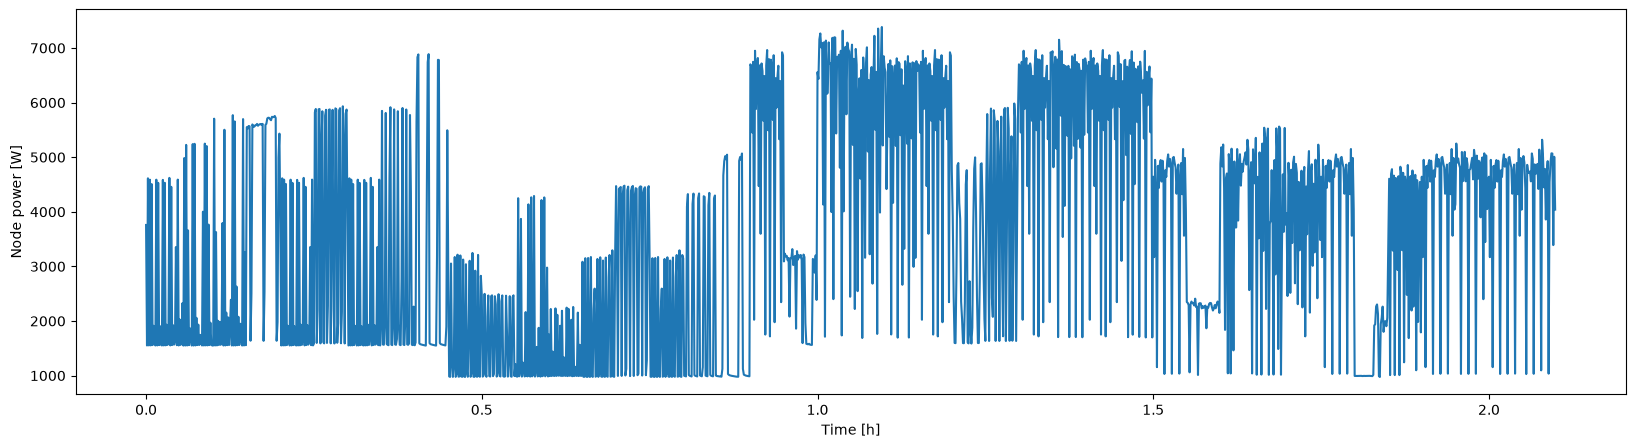

In [7]:
sample = 50
x = df[::sample]["time_s"] / 3600
y = df[::sample]["node_gpu_power_W"]


plt.figure(figsize=(20, 5))
plt.xlabel("Time [h]")
plt.ylabel("Node power [W]")

plt.plot(x, y)

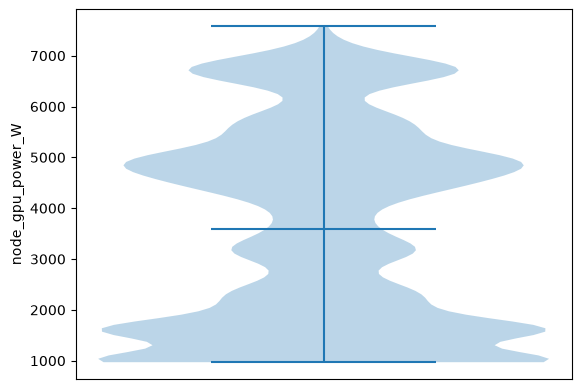

In [8]:
plt.violinplot(df["node_gpu_power_W"], showmeans=False, showmedians=True)

plt.ylabel("node_gpu_power_W")
plt.xticks([])
plt.show()

<Axes: xlabel='time_s'>

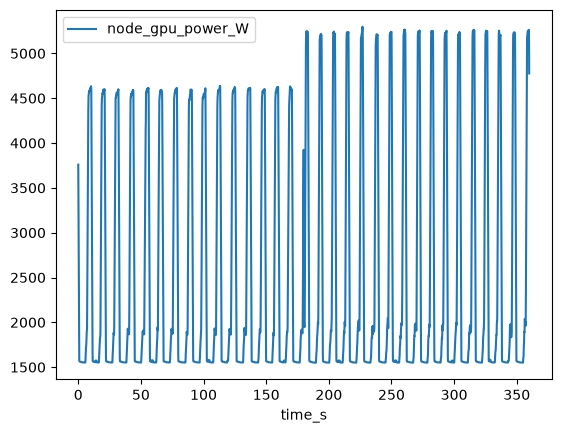

In [9]:
df.iloc[(df["segment_id"] == 1) | (df["segment_id"] == 2)].plot(
    "time_s", "node_gpu_power_W"
)

<Axes: xlabel='time_s'>

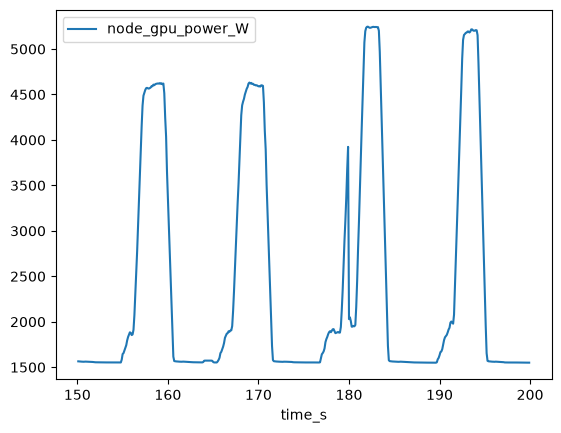

In [10]:
df.iloc[(df["time_s"] < 200) & (df["time_s"] > 150)].plot("time_s", "node_gpu_power_W")

Text(0.5, 1.0, 'gpu_temp_max_C')

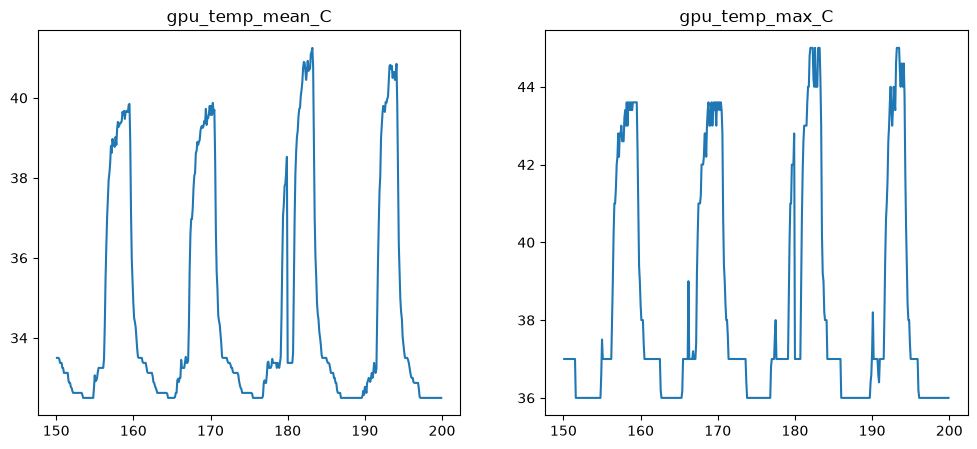

In [11]:
x = df.iloc[(df["time_s"] < 200) & (df["time_s"] > 150)]["time_s"]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(x, df.iloc[(df["time_s"] < 200) & (df["time_s"] > 150)]["gpu_temp_mean_C"])
ax[0].set_title("gpu_temp_mean_C")

ax[1].plot(x, df.iloc[(df["time_s"] < 200) & (df["time_s"] > 150)]["gpu_temp_max_C"])
ax[1].set_title("gpu_temp_max_C")

[27 40 26  6  7 36 16 20 15]


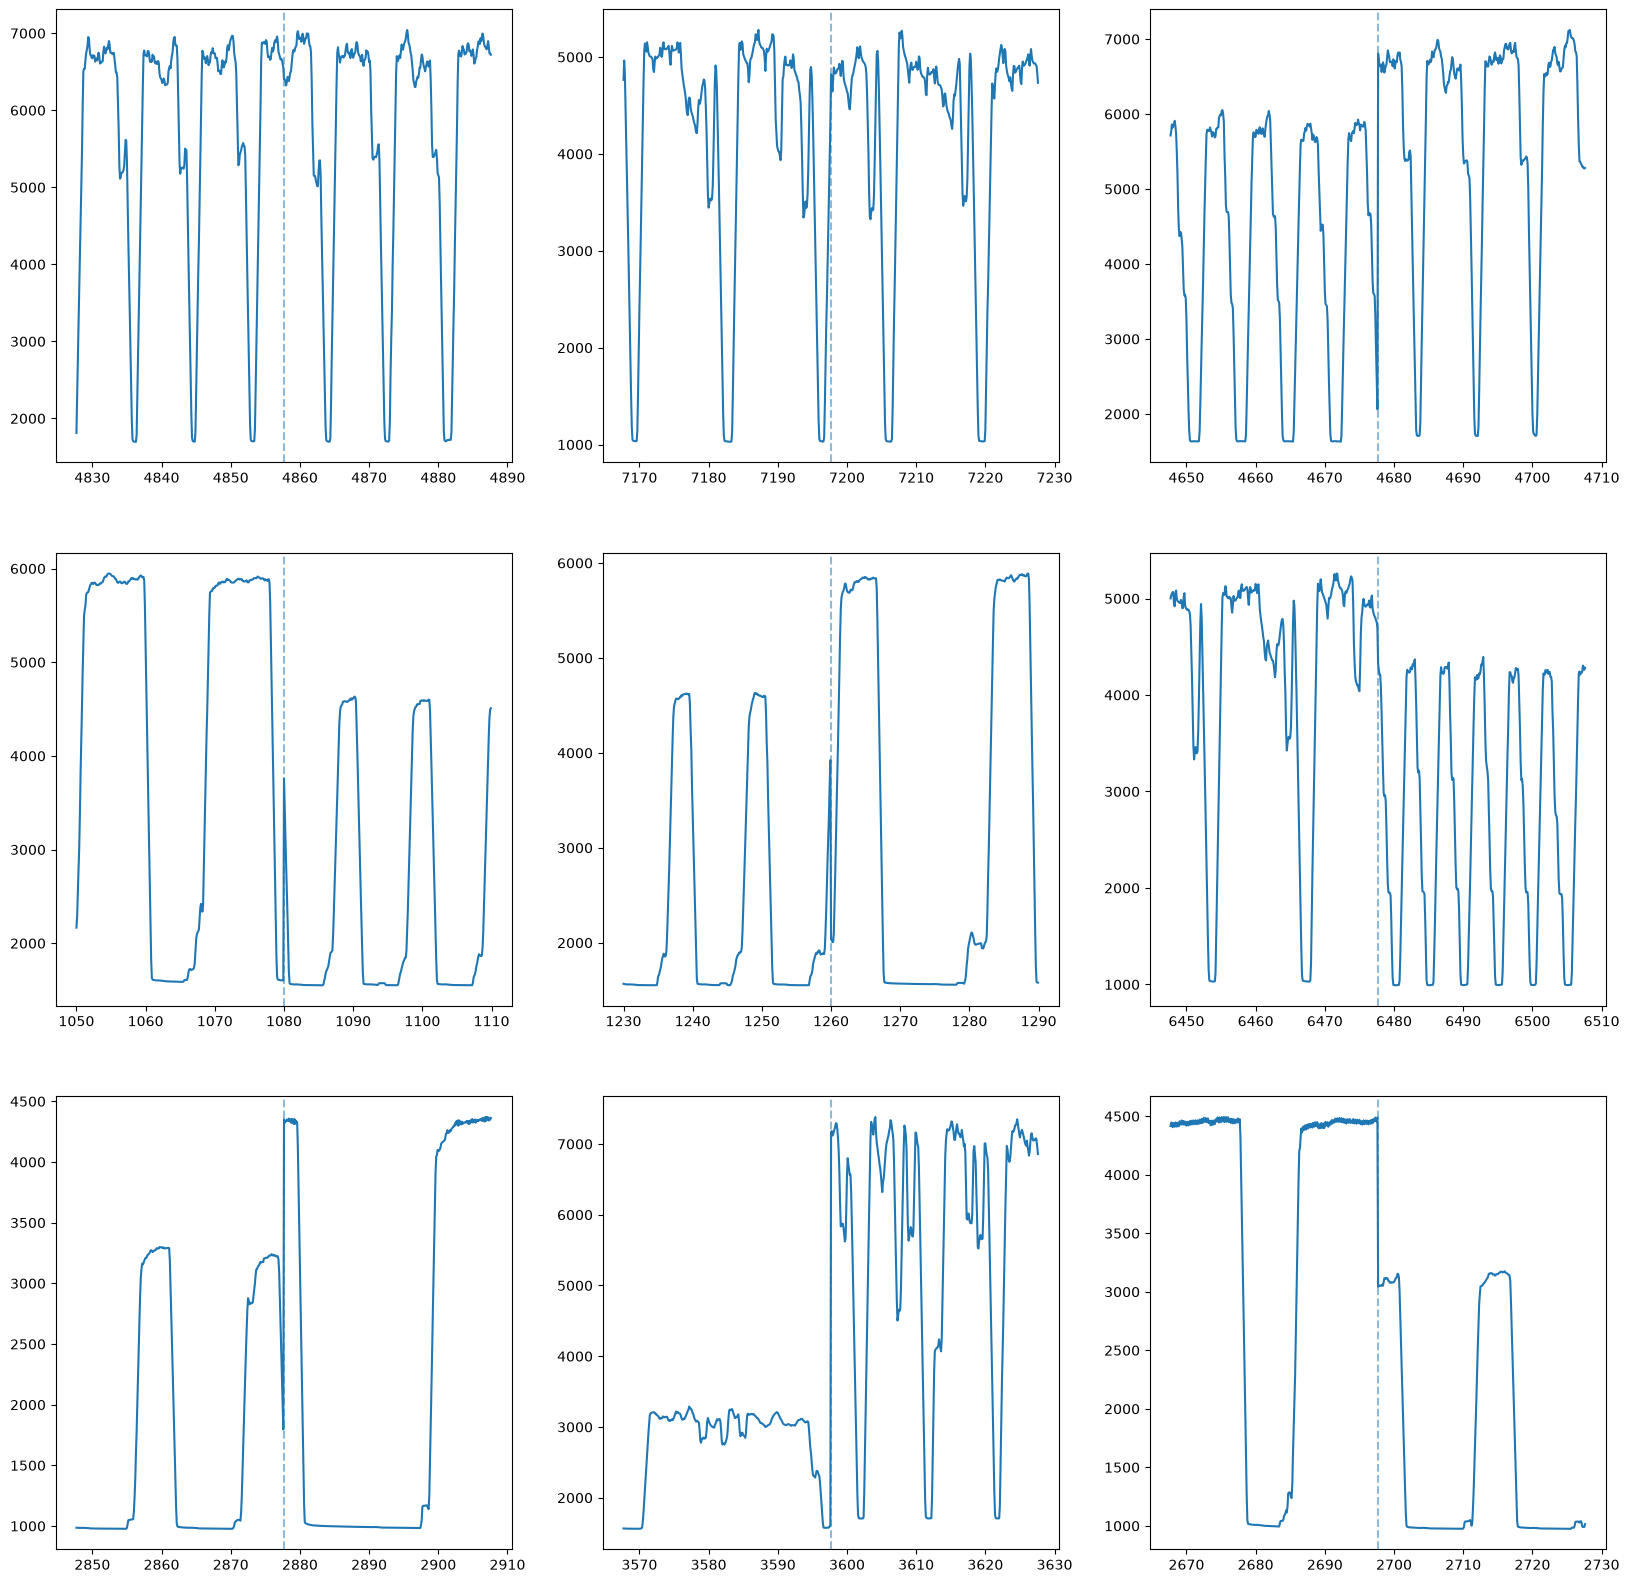

In [12]:
rng = np.random.default_rng(111)
sample = rng.choice(df["segment_id"].unique()[:-1], size=9, replace=False)
print(sample)


fig, ax = plt.subplots(3, 3, figsize=(20, 20))

for a, s in zip(ax.ravel(), sample):
    data = df.loc[(df["segment_id"] == s) | (df["segment_id"] == s + 1)]

    transition = (data["segment_id"] == s + 1) & (data["segment_id"].shift(1) == s)

    transition_idx = data.index[transition][0]
    stitch = data.loc[transition_idx]["time_s"]

    start = data["time_s"].min() + 150
    end = data["time_s"].max() - 150

    data = data.loc[(data["time_s"] >= start) & (data["time_s"] <= end)]

    a.plot(data["time_s"], data["node_gpu_power_W"])
    a.axvline(x=stitch, alpha=0.5, linestyle="--")

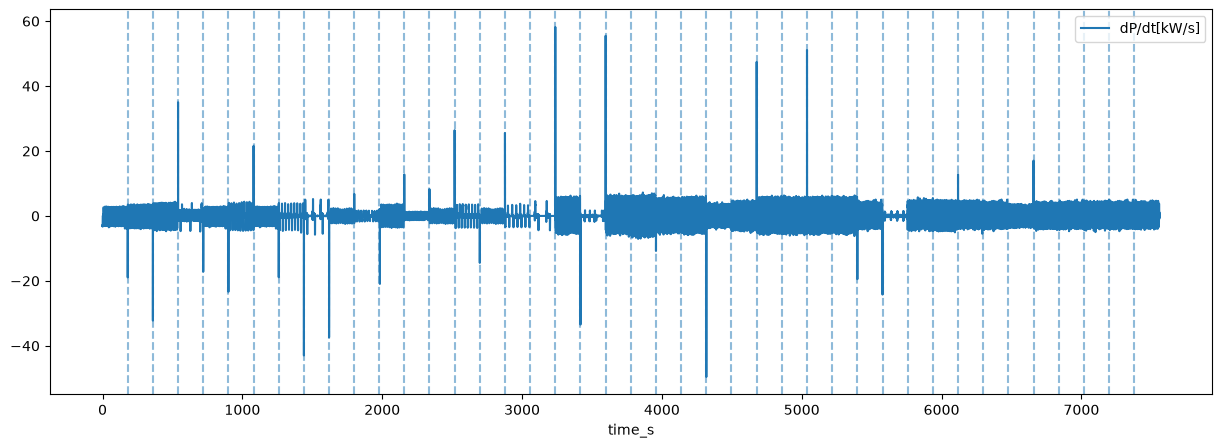

In [13]:
df["dP/dt[kW/s]"] = df["node_gpu_power_W"].diff() / df["time_s"].diff()

df["dP/dt[kW/s]"] /= 1000

ax = df.plot(x="time_s", y="dP/dt[kW/s]", figsize=(15, 5))

transitions = df["segment_id"].ne(df["segment_id"].shift())

transition_times = df.loc[transitions, "time_s"].iloc[1:]

for t in transition_times:
    ax.axvline(t, linestyle="--", alpha=0.5)

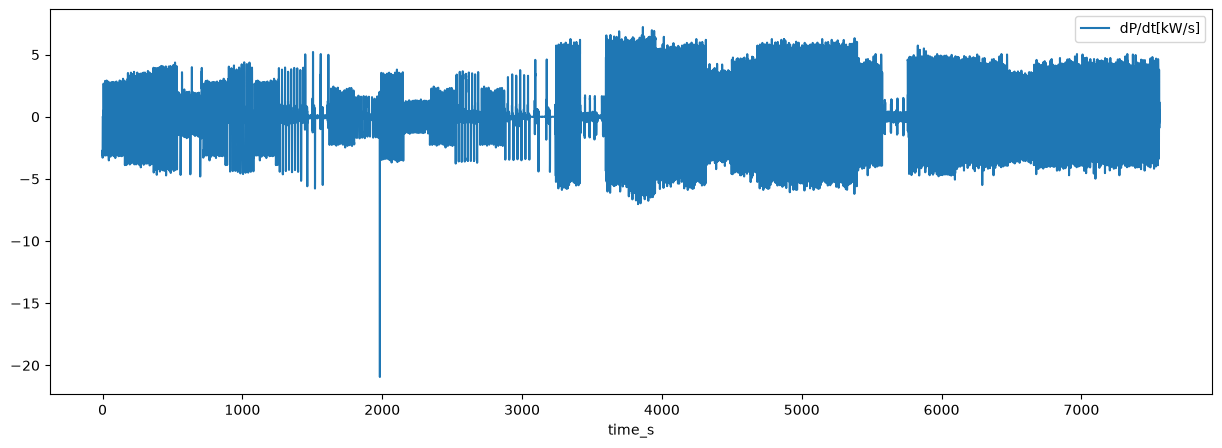

In [14]:
df["dP/dt[kW/s]"] = (
    df.groupby("segment_id")["node_gpu_power_W"].diff()
    / df.groupby("segment_id")["time_s"].diff()
)

df["dP/dt[kW/s]"] /= 1000

ax = df.plot(x="time_s", y="dP/dt[kW/s]", figsize=(15, 5))

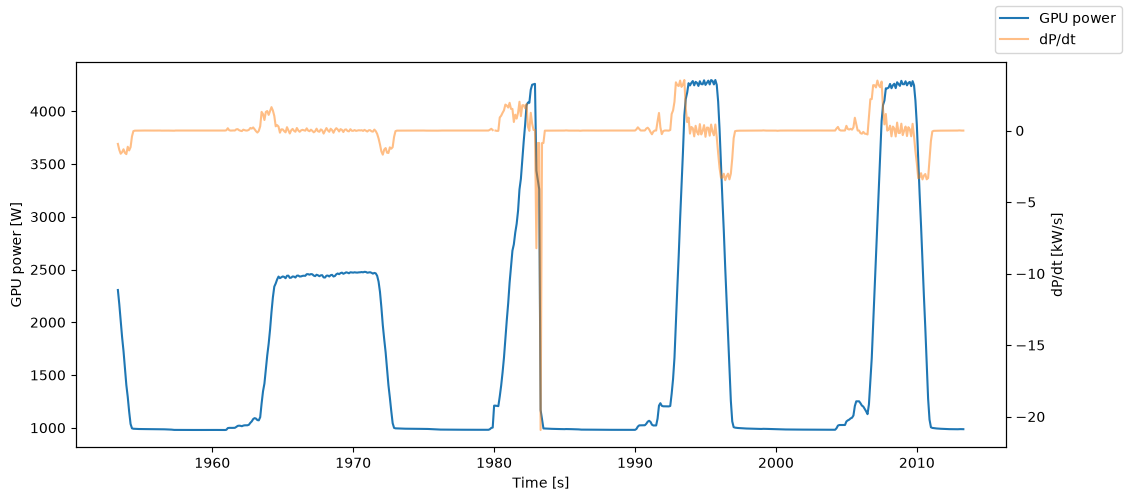

In [15]:
idx = df["dP/dt[kW/s]"].idxmin()
t_spike = df.loc[idx, "time_s"]

window = 30

data = df.loc[(df["time_s"] >= t_spike - window) & (df["time_s"] <= t_spike + window)]

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(data["time_s"], data["node_gpu_power_W"], label="GPU power")

ax1.set_xlabel("Time [s]")
ax1.set_ylabel("GPU power [W]")

ax2 = ax1.twinx()

ax2.plot(data["time_s"], data["dP/dt[kW/s]"], label="dP/dt", c="C1", alpha=0.5)

ax2.set_ylabel("dP/dt [kW/s]")

fig.legend()
plt.show()

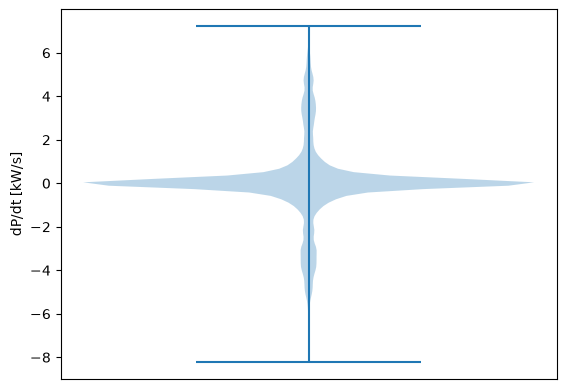

In [16]:
x = df["dP/dt[kW/s]"].dropna()
x = x.drop(x.idxmin())
plt.violinplot(x)
plt.ylabel("dP/dt [kW/s]")
plt.xticks([])
plt.show()

In [17]:
from scipy.integrate import cumulative_trapezoid

df["energy_kWh"] = (
    cumulative_trapezoid(df["node_gpu_power_W"], df["time_s"], initial=0) / 3_600_000
)

<Axes: >

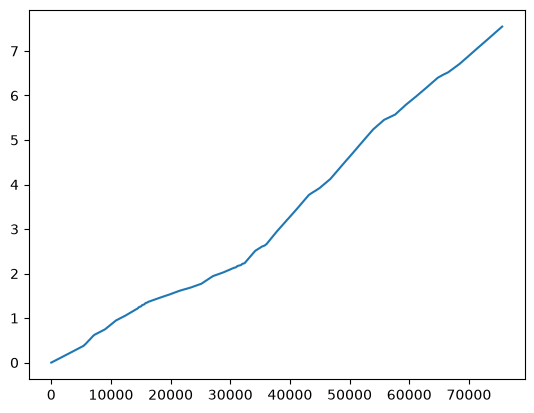

In [18]:
df["energy_kWh"].plot()